## Testowa analiza danych ze strony
https://cds.climate.copernicus.eu/datasets/derived-era5-single-levels-daily-statistics?tab=overview

In [1]:
import xarray as xr

ds = xr.open_dataset("7ebbd469f9350199b02b69eea0e93683.nc")
print(ds)

<xarray.Dataset> Size: 129MB
Dimensions:     (valid_time: 31, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 248B 2002-03-01 ... 2002-03-31
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
Data variables:
    tp          (valid_time, latitude, longitude) float32 129MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-03-16T12:53 GRIB to CDM+CF via cfgrib-0.9.1...


In [2]:
ds["tp"]


<xarray.DataArray 'tp' (valid_time: 31, latitude: 721, longitude: 1440)> Size: 129MB
[32185440 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 248B 2002-03-01 ... 2002-03-31
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [3]:
ds["tp"].attrs

{'GRIB_paramId': np.int64(228),
 'GRIB_dataType': 'fc',
 'GRIB_numberOfPoints': np.int64(1038240),
 'GRIB_typeOfLevel': 'surface',
 'GRIB_stepUnits': np.int64(1),
 'GRIB_stepType': 'accum',
 'GRIB_gridType': 'regular_ll',
 'GRIB_uvRelativeToGrid': np.int64(0),
 'GRIB_NV': np.int64(0),
 'GRIB_Nx': np.int64(1440),
 'GRIB_Ny': np.int64(721),
 'GRIB_cfName': 'unknown',
 'GRIB_cfVarName': 'tp',
 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid',
 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_iScansNegatively': np.int64(0),
 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_jPointsAreConsecutive': np.int64(0),
 'GRIB_jScansPositively': np.int64(0),
 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(90.0),
 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(-90.0),
 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(0.0),
 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(359.75),
 'GRIB_missingValue': np.float64(3.4028234663852886e+38),
 'GRIB_

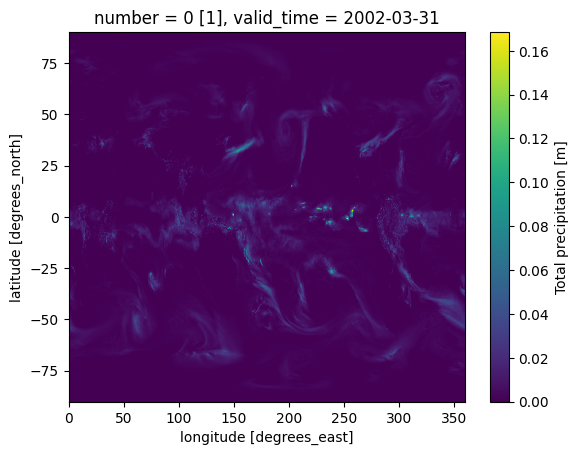

In [5]:
ds["tp"].isel(valid_time=30).plot()

In [6]:
ds["valid_time"].values[0]

np.datetime64('2002-03-01T00:00:00.000000000')

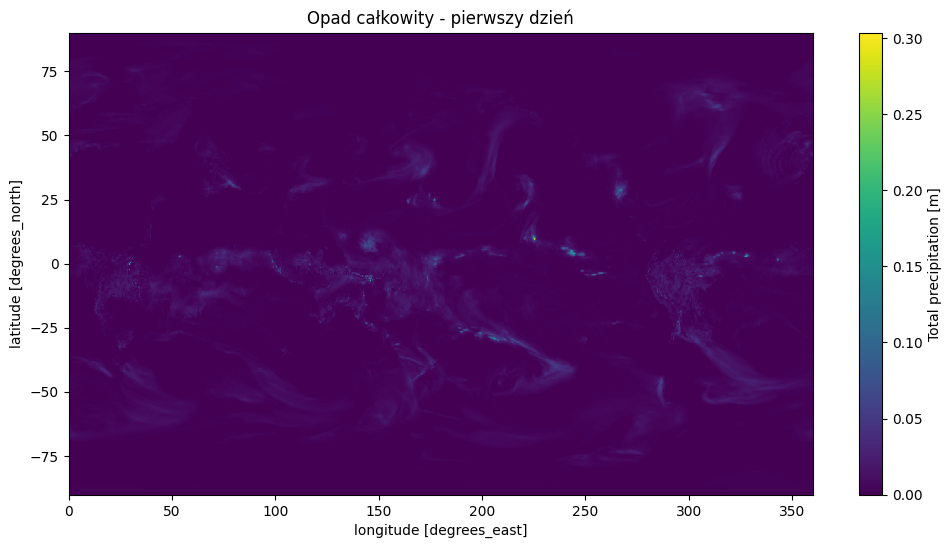

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
ds["tp"].isel(valid_time=0).plot()
plt.title("Opad całkowity - pierwszy dzień")
plt.show()

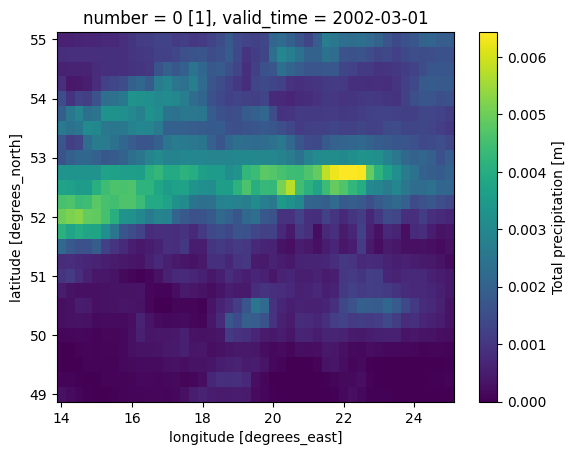

In [8]:
polska = ds.sel(latitude=slice(55, 49), longitude=slice(14, 25))
polska["tp"].isel(valid_time=0).plot()

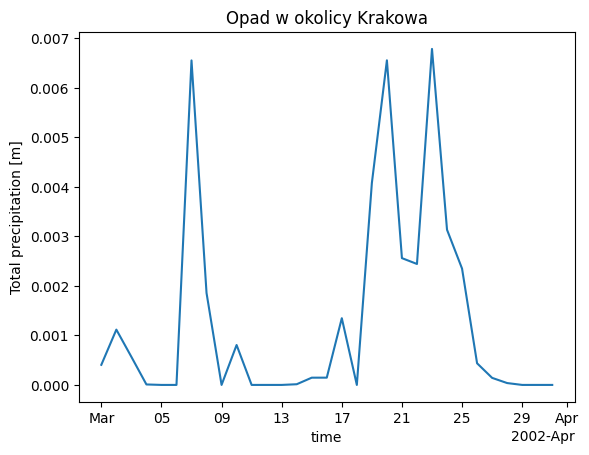

In [10]:
krakow["tp"].plot()
plt.title("Opad w okolicy Krakowa")
plt.show()

In [16]:
import cdsapi

client = cdsapi.Client()

dataset = "derived-era5-single-levels-daily-statistics"

request = {
    "product_type": "reanalysis",
    "variable": ["2m_temperature"],
    "year": ["2002"],
    "month": ["03"],
    "day": [
        "01","02","03","04","05","06","07","08","09","10",
        "11","12","13","14","15","16","17","18","19","20",
        "21","22","23","24","25","26","27","28","29","30","31"
    ],
    "daily_statistic": "daily_mean",
    "time_zone": "utc+00:00",
    "frequency": "1_hourly",

    "area": [55, 14, 49, 25]  # Polska
}

client.retrieve(dataset, request, "era5_poland_march_2002.zip")

2026-03-16 14:40:04,830 INFO Request ID is 2c184597-4c09-484e-b080-e2db0f17b66e
2026-03-16 14:40:04,899 INFO status has been updated to accepted
2026-03-16 14:40:18,461 INFO status has been updated to running
2026-03-16 14:41:21,118 INFO status has been updated to successful


830d8ab651d821b1e5010d21fbd5391c.nc:   0%|          | 0.00/97.8k [00:00<?, ?B/s]

'era5_poland_march_2002.zip'

In [18]:
import os
os.listdir()

['.ipynb_checkpoints',
 '7ebbd469f9350199b02b69eea0e93683.nc',
 'api.cdsapirc',
 'era5_poland_march_2002.zip',
 'projekt',
 'projekt_1.ipynb',
 'Zapisy_ADWNOZ_zespoły_2_3_osobowe.xlsx']

In [19]:
import xarray as xr

ds = xr.open_dataset("era5_poland_march_2002.zip")
ds

<xarray.Dataset> Size: 140kB
Dimensions:     (valid_time: 31, latitude: 25, longitude: 45)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 248B 2002-03-01 ... 2002-03-31
  * latitude    (latitude) float64 200B 55.0 54.75 54.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 360B 14.0 14.25 14.5 ... 24.5 24.75 25.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 140kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-03-16T13:40 GRIB to CDM+CF via cfgrib-0.9.1...

In [20]:
t2m = ds["t2m"] - 273.15

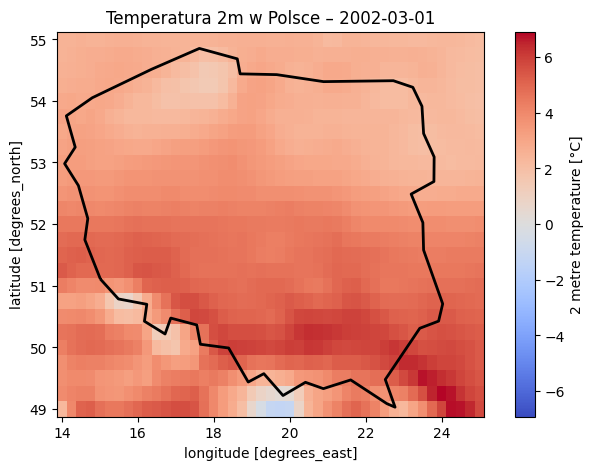

In [27]:
import matplotlib.pyplot as plt
import geopandas as gpd

# temperatura w °C
t2m = ds["t2m"] - 273.15

# granice Polski
url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/POL.geo.json"
poland = gpd.read_file(url)

# wspólny wykres
fig, ax = plt.subplots(figsize=(8,5))
t2m.attrs["units"] = "°C"
# mapa temperatury
t2m.isel(valid_time=0).plot(ax=ax, cmap="coolwarm")

# kontur Polski
poland.boundary.plot(ax=ax, color="black", linewidth=2)

plt.title("Temperatura 2m w Polsce – 2002-03-01")
plt.show()

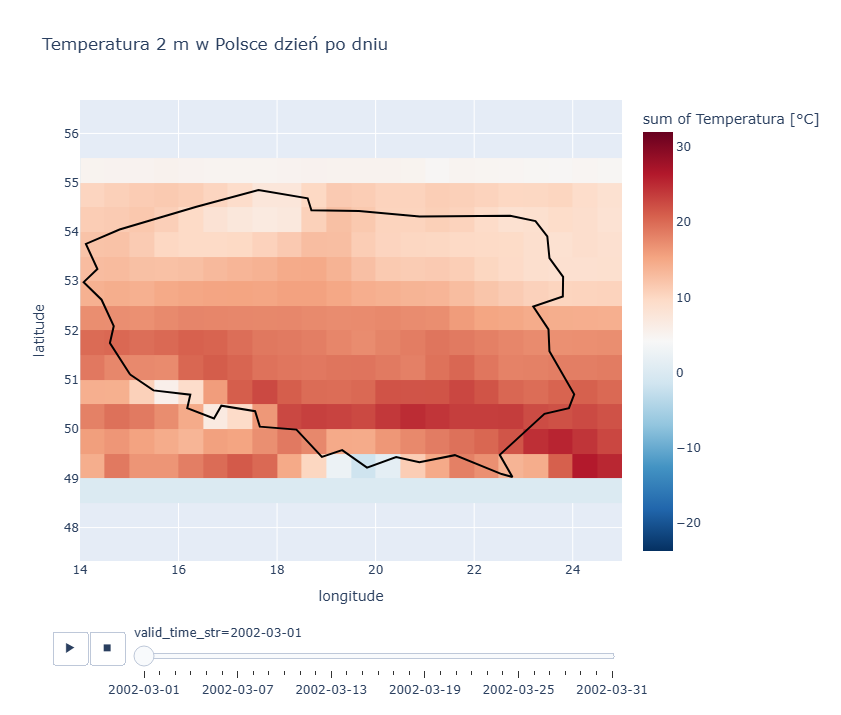

In [47]:
import geopandas as gpd
import plotly.graph_objects as go
import plotly.express as px

t2m = ds["t2m"] - 273.15
df = t2m.to_dataframe(name="temp").reset_index()
df["valid_time_str"] = df["valid_time"].dt.strftime("%Y-%m-%d")

tmin = df["temp"].min() -20
tmax = df["temp"].max() +20

fig = px.density_heatmap(
    df,
    x="longitude",
    y="latitude",
    z="temp",
    animation_frame="valid_time_str",
    nbinsx=len(df["longitude"].unique()),
    nbinsy=len(df["latitude"].unique()),
    color_continuous_scale="RdBu_r",
    range_color=(tmin, tmax),   # <<< stała skala kolorów
    labels={"temp": "Temperatura [°C]"},
    title="Temperatura 2 m w Polsce dzień po dniu"
)

url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/POL.geo.json"
poland = gpd.read_file(url)

geom = poland.geometry.iloc[0]

if geom.geom_type == "Polygon":
    x, y = geom.exterior.xy
    fig.add_trace(go.Scatter(
        x=list(x),
        y=list(y),
        mode="lines",
        line=dict(color="black", width=2),
        showlegend=False
    ))
else:
    for poly in geom.geoms:
        x, y = poly.exterior.xy
        fig.add_trace(go.Scatter(
            x=list(x),
            y=list(y),
            mode="lines",
            line=dict(color="black", width=2),
            showlegend=False
        ))

fig.update_layout(
    width=1000,
    height=700
)

fig.update_xaxes(range=[14, 25])
fig.update_yaxes(range=[49, 55], scaleanchor="x", scaleratio=1)

fig.show()

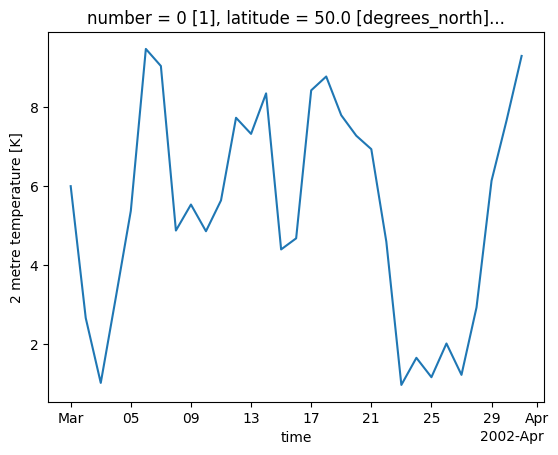

In [34]:
krakow = ds.sel(latitude=50.06, longitude=19.94, method="nearest")

temp = krakow["t2m"] - 273.15
temp.plot()

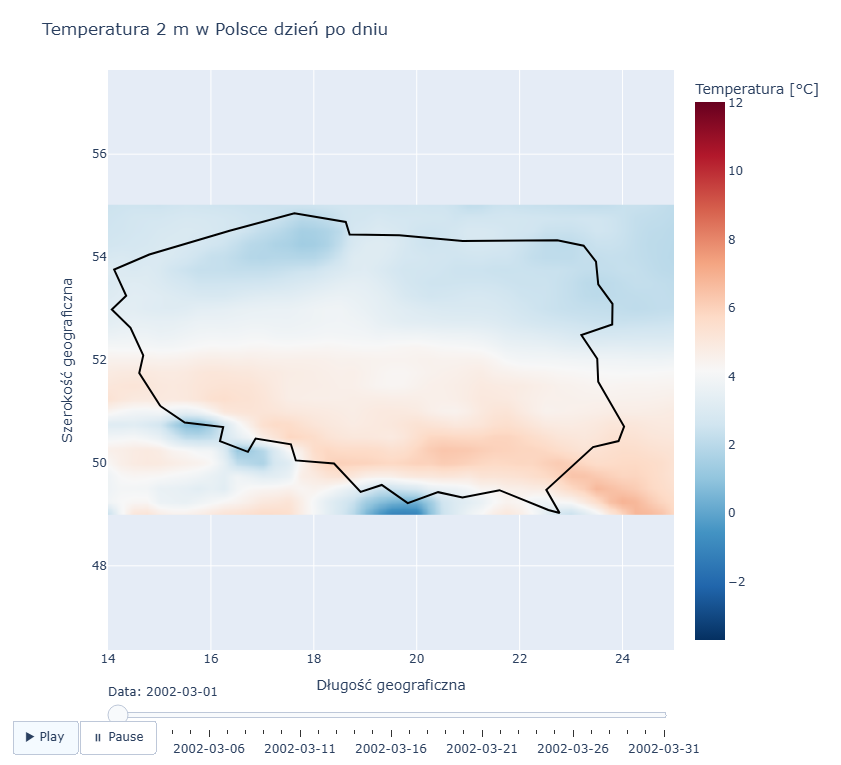

In [55]:
import xarray as xr
import numpy as np
import geopandas as gpd
import plotly.graph_objects as go

# =========================
# 1. Przygotowanie danych
# =========================

# temperatura w °C
t2m = ds["t2m"] - 273.15
t2m.attrs["units"] = "°C"

if "number" in t2m.dims:
    t2m = t2m.isel(number=0)

lon_min, lon_max = 14, 25
lat_min, lat_max = 49, 55

t2m = t2m.sel(longitude=slice(lon_min, lon_max), latitude=slice(lat_max, lat_min))

if t2m.latitude.values[0] > t2m.latitude.values[-1]:
    t2m = t2m.sortby("latitude")

# =========================
# DODANE: zagęszczenie siatki
# =========================
new_lons = np.linspace(float(t2m.longitude.min()), float(t2m.longitude.max()), 220)
new_lats = np.linspace(float(t2m.latitude.min()), float(t2m.latitude.max()), 180)

t2m = t2m.interp(longitude=new_lons, latitude=new_lats, method="linear")

zmin = float(t2m.min().values)
zmax = float(t2m.max().values)

times = t2m.valid_time.values
lons = t2m.longitude.values
lats = t2m.latitude.values

# =========================
# 2. Granica Polski
# =========================

url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/POL.geo.json"
poland = gpd.read_file(url)
geom = poland.geometry.iloc[0]

border_traces = []

if geom.geom_type == "Polygon":
    x, y = geom.exterior.xy
    border_traces.append(
        go.Scatter(
            x=list(x),
            y=list(y),
            mode="lines",
            line=dict(color="black", width=2),
            showlegend=False,
            hoverinfo="skip"
        )
    )
elif geom.geom_type == "MultiPolygon":
    for poly in geom.geoms:
        x, y = poly.exterior.xy
        border_traces.append(
            go.Scatter(
                x=list(x),
                y=list(y),
                mode="lines",
                line=dict(color="black", width=2),
                showlegend=False,
                hoverinfo="skip"
            )
        )

# =========================
# 3. Pierwsza klatka
# =========================

first_day = t2m.isel(valid_time=0)

heatmap = go.Heatmap(
    z=first_day.values,
    x=lons,
    y=lats,
    colorscale="RdBu_r",
    zmin=zmin,
    zmax=zmax,
    zsmooth="best",
    colorbar=dict(title="Temperatura [°C]"),
    hovertemplate="Lon: %{x}<br>Lat: %{y}<br>Temp: %{z:.2f} °C<extra></extra>"
)

# =========================
# 4. Klatki animacji
# =========================

frames = []
for i, t in enumerate(times):
    day_data = t2m.isel(valid_time=i)
    date_str = np.datetime_as_string(t, unit="D")

    frame_traces = [
        go.Heatmap(
            z=day_data.values,
            x=lons,
            y=lats,
            colorscale="RdBu_r",
            zmin=zmin,
            zmax=zmax,
            zsmooth="best",
            colorbar=dict(title="Temperatura [°C]"),
            hovertemplate="Lon: %{x}<br>Lat: %{y}<br>Temp: %{z:.2f} °C<extra></extra>"
        )
    ]

    for tr in border_traces:
        frame_traces.append(tr)

    frames.append(go.Frame(data=frame_traces, name=date_str))

# =========================
# 5. Suwak
# =========================

slider_steps = []
for t in times:
    date_str = np.datetime_as_string(t, unit="D")
    slider_steps.append(
        {
            "args": [
                [date_str],
                {
                    "frame": {"duration": 400, "redraw": True},
                    "mode": "immediate",
                    "transition": {"duration": 200}
                }
            ],
            "label": date_str,
            "method": "animate"
        }
    )

sliders = [
    {
        "active": 0,
        "currentvalue": {"prefix": "Data: "},
        "pad": {"t": 30},
        "steps": slider_steps
    }
]

# =========================
# 6. Przyciski play / pause
# =========================

updatemenus = [
    {
        "type": "buttons",
        "direction": "left",
        "buttons": [
            {
                "label": "▶ Play",
                "method": "animate",
                "args": [
                    None,
                    {
                        "frame": {"duration": 500, "redraw": True},
                        "fromcurrent": True,
                        "transition": {"duration": 10, "easing": "linear"}
                    }
                ]
            },
            {
                "label": "⏸ Pause",
                "method": "animate",
                "args": [
                    [None],
                    {
                        "frame": {"duration": 20, "redraw": False},
                        "mode": "immediate",
                        "transition": {"duration": 0}
                    }
                ]
            }
        ],
        "pad": {"r": 10, "t": 70},
        "showactive": True,
        "x": 0.1,
        "xanchor": "right",
        "y": 0,
        "yanchor": "top"
    }
]

# =========================
# 7. Złożenie figury
# =========================

fig = go.Figure(
    data=[heatmap] + border_traces,
    frames=frames
)

fig.update_layout(
    title="Temperatura 2 m w Polsce dzień po dniu",
    width=1000,
    height=750,
    xaxis=dict(
        title="Długość geograficzna",
        range=[lon_min, lon_max],
        constrain="domain"
    ),
    yaxis=dict(
        title="Szerokość geograficzna",
        range=[lat_min, lat_max],
        scaleanchor="x",
        scaleratio=1
    ),
    sliders=sliders,
    updatemenus=updatemenus,
    margin=dict(l=40, r=40, t=70, b=40)
)

fig.show()